# Fetal Health Classification — Practical Lab

This notebook is your hands-on workspace to **learn each of the 5 classifiers by doing**,
not by reading finished code. Every code cell below has a `# TODO` describing what to
write, plus hints. Fill them in yourself, run the cell, look at the output/plot, and
make sure you can explain *why* it looks the way it does before moving on.

If you get stuck: re-read the markdown above the cell, check the scikit-learn docs for
the function named in the hint, or ask your instructor for a *small* nudge — not the
answer.

**Dataset**: `data/raw/fetal_health.csv` — 2126 CTG exams, 21 numeric features,
target `NSP` (1=Normal, 2=Suspect, 3=Pathological).


## 1. Load & look at the data

Before touching any model, you always look at the raw data first: how many rows/columns,
what types, any obvious issues.

**TODO:**
1. Import `pandas` as `pd`.
2. Read `../data/raw/fetal_health.csv` into a DataFrame called `df`.
3. Print `df.shape`.
4. Show `df.head()`.
5. Show `df.info()` — check: are there any missing values? What dtype is every column?


In [7]:
import pandas as pd

df = pd.read_csv('./data/raw/fetal_health.csv')

print(df.shape)
print(df.head())
print(df.info())


(2126, 23)
    LB     AC   FM     UC     DL   DS   DP  ASTV  MSTV  ALTV  ...  Max  Nmax  \
0  120  0.000  0.0  0.000  0.000  0.0  0.0    73   0.5    43  ...  126     2   
1  132  0.006  0.0  0.006  0.003  0.0  0.0    17   2.1     0  ...  198     6   
2  133  0.003  0.0  0.008  0.003  0.0  0.0    16   2.1     0  ...  198     5   
3  134  0.003  0.0  0.008  0.003  0.0  0.0    16   2.4     0  ...  170    11   
4  132  0.007  0.0  0.008  0.000  0.0  0.0    16   2.4     0  ...  170     9   

   Nzeros  Mode  Mean  Median  Variance  Tendency  CLASS  NSP  
0       0   120   137     121        73         1      9    2  
1       1   141   136     140        12         0      6    1  
2       1   141   135     138        13         0      6    1  
3       0   137   134     137        13         1      6    1  
4       0   137   136     138        11         1      2    1  

[5 rows x 23 columns]
<class 'pandas.DataFrame'>
RangeIndex: 2126 entries, 0 to 2125
Data columns (total 23 columns):
 #   

## 2. Drop the leaked column

The raw file has a `CLASS` column — a *different*, more granular diagnostic code that is
**not** one of the 21 official input features. If you leave it in, you risk the model
learning from a column that's really just another form of the answer.

**TODO:** drop the `CLASS` column from `df` (keep `NSP`, that's our target).


In [8]:
df = df.drop(columns=['CLASS'])


## 3. Understand the target: class imbalance

**Concept:** In classification, "class imbalance" means some classes have far more
examples than others. Here, most CTG exams are Normal. A model could get high accuracy
by *always* predicting "Normal" and still be clinically useless — it would never catch
an at-risk pregnancy. That's why metrics like Precision/Recall/F1/MCC per class matter
more than plain accuracy for imbalanced problems.

**TODO:**
1. Use `df['NSP'].value_counts()` to see the raw counts.
2. Make a bar plot of these counts using `matplotlib` or `seaborn` (`sns.countplot`).
3. In a markdown cell or comment, write down the % share of each class.


NSP
1    1655
2     295
3     176
Name: count, dtype: int64


<Axes: xlabel='NSP', ylabel='count'>

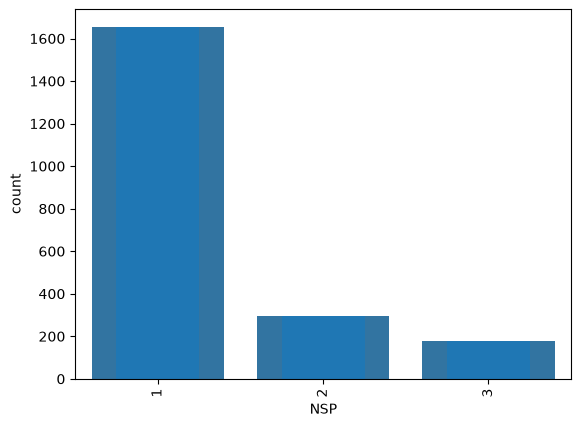

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

print(df['NSP'].value_counts())

sns.countplot(data=df, x='NSP')  
df['NSP'].value_counts().plot(kind='bar')

## 4. Feature distributions & correlation

**Concept:** Some models (Naive Bayes) assume features are independent of each other
given the class. Others (Logistic Regression, SVM, KNN) are sensitive to feature scale
(a feature ranging 0-200 can dominate one ranging 0-1 unless you standardize them).

**TODO:**
1. Plot histograms of a few interesting features (try `LB`, `ASTV`, `Mean`, `Variance`)
   using `df[...].hist(figsize=(12,8))` or a loop with `plt.subplots`.
2. Compute the correlation matrix with `df.drop(columns=['NSP']).corr()` and visualize
   it with `sns.heatmap(...)`.
3. Look specifically at `Mean`, `Median`, `Mode`, `Variance` in the heatmap — are they
   strongly correlated with each other? Keep this in mind for the Naive Bayes section
   later.


<Axes: >

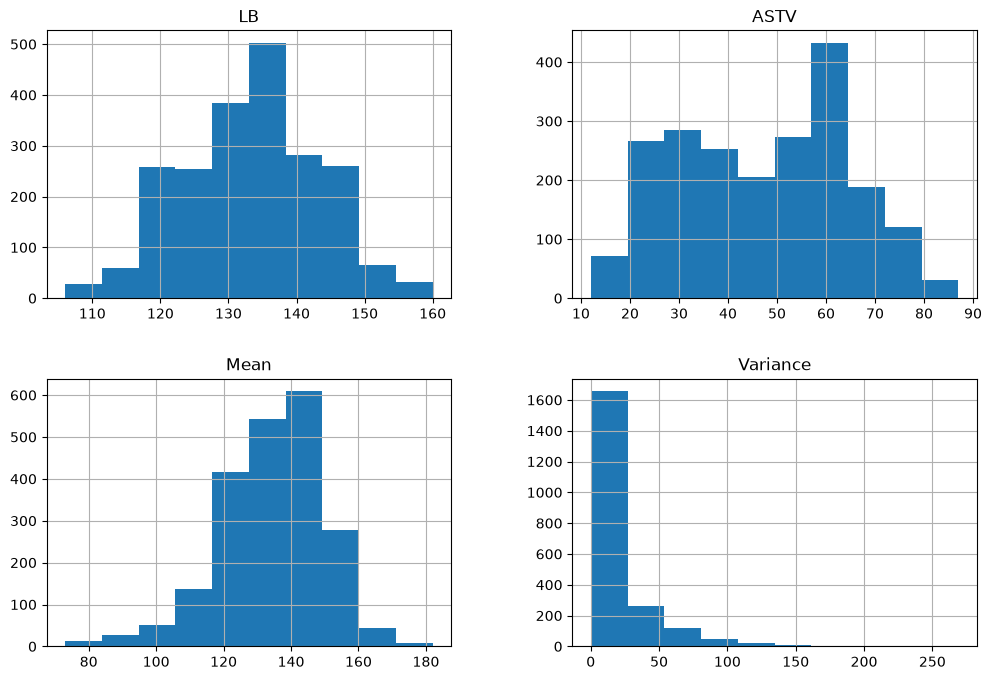

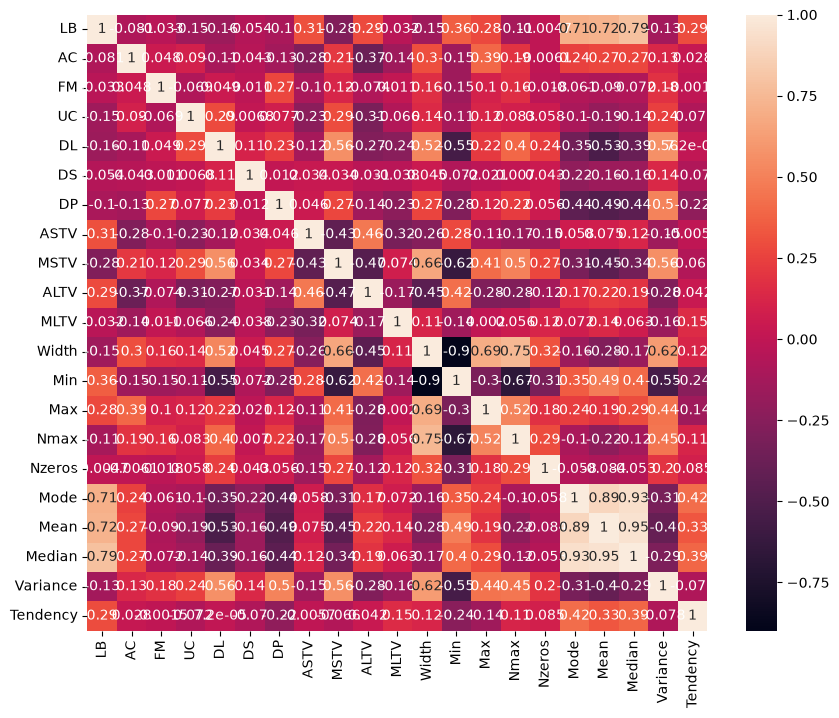

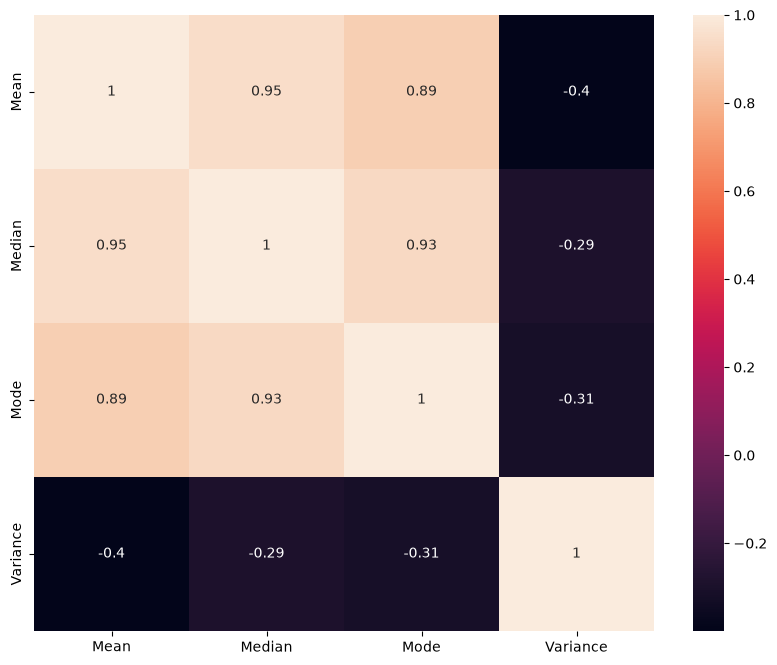

In [17]:
#histograms of a few features, then a correlation heatmap
df[['LB','ASTV','Mean','Variance']].hist(figsize=(12,8))
corr_matrix = df.drop(columns=['NSP']).corr()
plt.figure(figsize=(10, 8))
sns.heatmap(data= corr_matrix, annot=True)
plt.figure(figsize=(10, 8))
small_corr = df[['Mean', 'Median', 'Mode', 'Variance']].corr()
sns.heatmap(data= small_corr, annot=True)

## 5. Train/test split — and why we stratify

**Concept:** We hold out a test set that the model never sees during training, so we can
honestly measure how well it generalizes. For imbalanced data, a *plain random* split
risks putting too few (or zero) rare-class ("Pathological") samples in the test set by
chance. `stratify=y` forces both splits to keep the same class ratios as the full
dataset.

**TODO:**
1. Import `train_test_split` from `sklearn.model_selection`.
2. Split `X` (all columns except `NSP`) and `y` (`NSP`) into `X_train, X_test, y_train,
   y_test`, with `test_size=0.2`, `random_state=42`, and `stratify=y`.
3. Print `y_train.value_counts(normalize=True)` and `y_test.value_counts(normalize=True)`
   — confirm the class proportions match.


In [27]:
# train/test split with stratification
from sklearn.model_selection import train_test_split

y = df['NSP']
X = df.drop(columns=['NSP'])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(y_train.value_counts(normalize=True)) 
print(y_test.value_counts(normalize=True))

NSP
1    0.778235
2    0.138824
3    0.082941
Name: proportion, dtype: float64
NSP
1    0.779343
2    0.138498
3    0.082160
Name: proportion, dtype: float64


## 6. Feature scaling

**Concept:** `StandardScaler` transforms each feature to have mean 0 and standard
deviation 1. Distance-based and gradient-based algorithms (KNN, SVM, Logistic
Regression) need this — without it, a feature like `Width` (range ~3-180) would swamp a
feature like `AC` (range ~0-0.02) purely because of units, not real importance.

**Important rule:** fit the scaler ONLY on `X_train`, then use that *same* fitted scaler
to transform `X_test`. Never fit on test data — that would leak test-set information
into preprocessing.

**TODO:**
1. Import `StandardScaler` from `sklearn.preprocessing`.
2. `fit_transform` it on `X_train` -> `X_train_scaled`.
3. `transform` (not fit_transform!) it on `X_test` -> `X_test_scaled`.


In [33]:
# scale X_train and X_test correctly
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


## 7. Model 1 — Logistic Regression

**Concept:** Despite the name, this is a *classification* model. For each class, it
learns a linear combination of features and squashes it through a sigmoid/softmax
function to get a probability. Its decision boundary is a straight line/plane/hyperplane
in feature space — it cannot capture curved boundaries.

**TODO:**
1. Import `LogisticRegression` from `sklearn.linear_model`.
2. Create it with `max_iter=1000` and `random_state=42`, fit it on the scaled training
   data.
3. Get predictions (`.predict`) and probabilities (`.predict_proba`) on the scaled test
   data.
4. Print `accuracy_score(y_test, y_pred)`.


In [ ]:
# TODO: train Logistic Regression and get predictions
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score



### 7b. Evaluate it properly: confusion matrix + all 6 metrics

**Concept:** A confusion matrix shows, for each true class, how predictions were
distributed across predicted classes — it's the most honest way to see *where* a model
goes wrong (e.g. confusing Suspect with Normal vs. with Pathological).

**TODO:**
1. Import `confusion_matrix`, `precision_score`, `recall_score`, `f1_score`,
   `matthews_corrcoef`, `roc_auc_score` from `sklearn.metrics`.
2. Compute and print all 6 metrics (Accuracy, AUC, Precision, Recall, F1, MCC) — use
   `average='macro'` for Precision/Recall/F1/AUC (we chose macro averaging so rare
   classes like Pathological count just as much as Normal — see the project README for
   why).
3. Plot the confusion matrix with `sns.heatmap(confusion_matrix(...), annot=True,
   fmt='d')`.


In [ ]:
# TODO: compute all 6 metrics + plot confusion matrix for Logistic Regression
from sklearn.metrics import (
    confusion_matrix, precision_score, recall_score, f1_score,
    matthews_corrcoef, roc_auc_score,
)



### 7c. Visualizing AUC: the ROC curve

**Concept:** AUC is the area under the ROC curve, which plots True Positive Rate vs.
False Positive Rate as you sweep the classification threshold from 0 to 1. A model that
ranks positives above negatives well (even if its hard 0/1 predictions aren't perfect)
gets a high AUC.

For a 3-class problem, you plot one ROC curve per class using the "one-vs-rest" trick:
treat class `c` as positive and everything else as negative.

**TODO:**
1. Import `roc_curve` from `sklearn.metrics` and `label_binarize` from
   `sklearn.preprocessing`.
2. Binarize `y_test` for the 3 classes.
3. For each class, compute `roc_curve(y_test_binarized[:, i], y_proba[:, i])` and plot
   it on the same axes with `plt.plot`. Add the diagonal "random guess" line for
   reference.


In [ ]:
# TODO: one-vs-rest ROC curves for Logistic Regression, one line per class
from sklearn.metrics import roc_curve
from sklearn.preprocessing import label_binarize



## 8. Model 2 — Decision Tree

**Concept:** A tree repeatedly splits the data on the feature/threshold that best
separates classes (measured by Gini impurity or entropy), forming a tree of yes/no
questions. Deeper trees fit training data better but can **overfit** — memorizing noise
instead of learning general patterns.

**TODO — overfitting experiment:**
1. Import `DecisionTreeClassifier`.
2. Loop over `max_depth` values, e.g. `range(1, 20)`. For each depth: train a tree,
   record **training accuracy** and **test accuracy**.
3. Plot both curves (train acc vs depth, test acc vs depth) on the same chart.
4. Look at where the two curves start to diverge — that's roughly where overfitting
   begins. Pick a reasonable `max_depth` based on this plot (we used 8 in the main
   project; does your plot agree it's a reasonable choice?).


In [ ]:
# TODO: loop over max_depth, record train/test accuracy, plot both curves
from sklearn.tree import DecisionTreeClassifier

depths = range(1, 20)
train_accs, test_accs = [], []



### 8b. Visualize the tree itself

**TODO:** Train one `DecisionTreeClassifier` with your chosen `max_depth` (try a small
value like 3 first, just so the plot is readable), then use
`sklearn.tree.plot_tree(model, feature_names=X.columns, class_names=['Normal','Suspect','Pathological'], filled=True)`
to see the actual decision rules it learned. Can you read off the first split and explain
it in plain English?


In [ ]:
# TODO: train a shallow tree and visualize it with plot_tree
from sklearn.tree import plot_tree



### 8c. Evaluate the Decision Tree with all 6 metrics

**TODO:** repeat the same metric computation + confusion matrix you did for Logistic
Regression, using your chosen `max_depth` model this time.

**Think about this while you look at the AUC specifically:** a tree's predicted
"probability" for a leaf is just the fraction of training samples of each class in that
leaf. How many distinct probability values can a tree with `max_depth=8` even produce (at
most `2**8` leaves)? How might that affect ROC/AUC compared to a model like Logistic
Regression that outputs a smooth probability for every single point?


In [ ]:
# TODO: metrics + confusion matrix for the Decision Tree


## 9. Model 3 — K-Nearest Neighbors (KNN)

**Concept:** To classify a new point, KNN looks at the `k` closest points (by distance)
in the *training* data and takes a majority vote of their labels. No real "training"
happens — all the work happens at prediction time. This is why scaling matters so much
here: distance is meaningless if features have wildly different units/ranges.

**TODO — choosing k experiment:**
1. Import `KNeighborsClassifier`.
2. Loop over `k` values, e.g. `[1, 3, 5, 7, 9, 11, 15, 21, 31]`. For each k: train on
   scaled training data, record test accuracy.
3. Plot test accuracy vs. k. What happens at very small k (k=1)? What happens as k gets
   very large? Which k would you pick, and why?
4. Train your chosen k, compute all 6 metrics, and look specifically at **Recall** for
   the Pathological class. Given only ~8% of data is Pathological, what do you expect to
   happen to a true Pathological point's "5 nearest neighbors" — are they likely to
   mostly be Normal? What does that do to recall for the rare class?


In [ ]:
# TODO: loop over k, plot accuracy vs k, then evaluate your chosen k fully
from sklearn.neighbors import KNeighborsClassifier

k_values = [1, 3, 5, 7, 9, 11, 15, 21, 31]
test_accs_knn = []



## 10. Model 4 — Naive Bayes

**Concept:** Naive Bayes applies Bayes' theorem, assuming every feature is
**conditionally independent** given the class. `GaussianNB` additionally assumes each
feature follows a normal (Gaussian) distribution within each class.

Go back to the correlation heatmap you made in Section 4. Features like `Mean`,
`Median`, `Mode`, and `Variance` are all statistics computed from the *same* underlying
heart-rate histogram — they are naturally correlated. Naive Bayes multiplies each
feature's "evidence" independently, so when features are actually correlated, their
shared signal gets effectively double-counted, distorting the predicted probabilities.

**TODO:**
1. Train `GaussianNB` on the scaled training data.
2. Compute all 6 metrics. Compare its Precision specifically against Logistic
   Regression/Decision Tree/SVM — is it noticeably lower? Does the independence
   assumption violation explain why?
3. Optional visualization: for one feature (e.g. `Mean`), plot its distribution
   separately for each class (`sns.kdeplot` or `sns.histplot` with `hue='NSP'`) — does it
   actually look roughly Gaussian (bell-shaped) per class?


In [ ]:
# TODO: train GaussianNB, evaluate with all 6 metrics
from sklearn.naive_bayes import GaussianNB



## 11. Model 5 — Support Vector Machine (SVM)

**Concept:** An SVM tries to find the decision boundary ("hyperplane") that has the
**maximum margin** — the largest possible gap — between classes. With a linear kernel it
can only draw straight boundaries; with an RBF (Radial Basis Function) kernel, it can
implicitly map data into a higher-dimensional space and draw *curved* boundaries,
without ever explicitly computing that higher-dimensional space (the "kernel trick").

**TODO:**
1. Train two SVMs: one with `kernel='linear'`, one with `kernel='rbf'` (both with
   `probability=True, random_state=42`).
2. Compute all 6 metrics for both. Which kernel does better, and does that tell you
   whether the classes are linearly separable or not?
3. For the RBF model, compare its AUC against all the other models you've trained so
   far. RBF+`probability=True` uses Platt scaling internally to produce well-calibrated
   probabilities — does that line up with what you see?


In [ ]:
# TODO: train linear-kernel and rbf-kernel SVMs, compare their metrics
from sklearn.svm import SVC



### 11b. Bonus: visualize an SVM decision boundary in 2D

Real decision boundaries live in 21-dimensional space, which we can't plot. But we can
build a toy 2D version to *see* the concept.

**TODO:**
1. Pick just 2 features (e.g. `ASTV` and `MSTV` — or any two you find interesting from
   the correlation heatmap).
2. Train an RBF-kernel SVM using **only** those 2 (scaled) features.
3. Create a mesh grid over the 2D feature space (`numpy.meshgrid`), predict the class
   for every point on the grid, and plot it as a filled contour (`plt.contourf`)
   underneath a scatter plot of the real training points colored by class.
4. This is the classic "SVM decision boundary" picture — do you see curved regions?


In [ ]:
# TODO: 2-feature SVM + decision boundary contour plot
import numpy as np



## 12. Final comparison — all 5 models side by side

**TODO:**
1. Collect the 6 metrics for all 5 models (Logistic Regression, Decision Tree, KNN,
   Naive Bayes, SVM-rbf) into one DataFrame, with models as rows and metrics as columns.
2. Display it.
3. Make a grouped bar chart comparing all models across all metrics (`df.plot(kind='bar',
   figsize=(12,6))` works well here).
4. Compare your numbers here against `model/metrics.json` from the main project (same
   split, same random_state — they should match closely).


In [ ]:
# TODO: build the comparison DataFrame and bar chart


## 13. Reflection questions

Answer these in a markdown cell, in your own words, based on what you actually observed
in your plots above (not from theory alone):

1. Which model had the best AUC, and which had the worst? Why, mechanically, does that
   match what you saw in its ROC curve / probability outputs?
2. Which model had the best Recall on the rare Pathological class? Which had the worst,
   and why (tie it back to how that model makes decisions)?
3. Did the Decision Tree's train-vs-test accuracy plot (Section 8) show overfitting at
   high depth? At what depth did it start?
4. If you were deploying ONE of these models for real clinical triage, which would you
   pick, and would you optimize for AUC, Recall, or something else? Why?

Carry your answers over into the project `README.md` "Observations" table.
